In [1]:
import os
import cv2
import time
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from scipy.stats import skew

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import (
    SelectKBest,
    f_classif,
    VarianceThreshold,
    SelectFromModel
)
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

from sklearn.svm import SVC
from sklearn.ensemble import (
    ExtraTreesClassifier,
    RandomForestClassifier,
    VotingClassifier,
    StackingClassifier
)

from skimage.feature import (
    hog,
    local_binary_pattern,
    graycomatrix,
    graycoprops
)

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)


In [2]:
DATASET = "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup"

TRAIN_DIR = os.path.join(DATASET, "train")
TEST_DIR = os.path.join(DATASET, "test_warmup")

IMAGE_SIZE = 128

CACHE_DIR = "features_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

## 1. Đọc danh sách lớp và tạo DataFrame train/test

In [3]:
classes = sorted(os.listdir(TRAIN_DIR))
print("Số lớp:", len(classes))
print(classes)

Số lớp: 8
['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Narrow Brown Leaf Spot', 'Rice Hispa', 'Sheath Blight']


In [4]:
rows = []

for label in classes:
    folder = os.path.join(TRAIN_DIR, label)
    for img in os.listdir(folder):
        rows.append({
            "image_id": img,
            "label": label,
            "path": os.path.join(folder, img)
        })

train_df = pd.DataFrame(rows)
print("Số ảnh train:", len(train_df))
train_df["label"].value_counts()

Số ảnh train: 2026


label
Leaf Blast                360
Sheath Blight             352
Brown Spot                289
Rice Hispa                260
Bacterial Leaf Blight     226
Leaf scald                220
Healthy Rice Leaf         193
Narrow Brown Leaf Spot    126
Name: count, dtype: int64

In [5]:
label2id = {c: i for i, c in enumerate(classes)}
id2label = {v: k for k, v in label2id.items()}

train_df["target"] = train_df["label"].map(label2id)
train_df.head()

,image_id,label,path,target
0,aug_train_0089.jpg,Bacterial Leaf Blight,/kaggle/input/competitions/fptu-can-tho-olympi...,0
1,Bacterial_leaf_Blight (157).jpg,Bacterial Leaf Blight,/kaggle/input/competitions/fptu-can-tho-olympi...,0
2,aug_train_0110.jpg,Bacterial Leaf Blight,/kaggle/input/competitions/fptu-can-tho-olympi...,0
3,aug_train_0590.jpg,Bacterial Leaf Blight,/kaggle/input/competitions/fptu-can-tho-olympi...,0
4,Bacterial_leaf_Blight (55).jpg,Bacterial Leaf Blight,/kaggle/input/competitions/fptu-can-tho-olympi...,0


In [6]:
test_images = sorted(os.listdir(TEST_DIR))

test_df = pd.DataFrame({
    "image_id": test_images,
    "path": [os.path.join(TEST_DIR, i) for i in test_images]
})

test_df.head()

,image_id,path
0,public_0001.jpg,/kaggle/input/competitions/fptu-can-tho-olympi...
1,public_0002.jpg,/kaggle/input/competitions/fptu-can-tho-olympi...
2,public_0003.jpg,/kaggle/input/competitions/fptu-can-tho-olympi...
3,public_0004.jpg,/kaggle/input/competitions/fptu-can-tho-olympi...
4,public_0005.jpg,/kaggle/input/competitions/fptu-can-tho-olympi...


## 2. Trích xuất đặc trưng — chỉ dùng Machine Learning cổ điển (không CNN/Deep Learning)


In [7]:

def apply_clahe(img_bgr):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_eq = clahe.apply(l)
    lab_eq = cv2.merge([l_eq, a, b])
    return cv2.cvtColor(lab_eq, cv2.COLOR_LAB2BGR)


HOG_CELL_SIZES = [(8, 8), (16, 16), (32, 32)]

def extract_hog_multiscale(gray):
    feats = []
    for cell in HOG_CELL_SIZES:
        f = hog(
            gray,
            orientations=9,
            pixels_per_cell=cell,
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True
        )
        feats.append(f)
    return np.concatenate(feats).astype(np.float32)


LBP_RADII = [1, 2, 3]

def extract_lbp_multiradius(gray):
    feats = []
    for R in LBP_RADII:
        P = 8 * R
        lbp = local_binary_pattern(gray, P=P, R=R, method="uniform")
        n_bins = P + 2
        hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, n_bins + 1), range=(0, n_bins))
        hist = hist.astype("float32")
        hist /= (hist.sum() + 1e-6)
        feats.append(hist)
    return np.concatenate(feats).astype(np.float32)


GLCM_ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
GLCM_DISTANCES = [1, 2]
GLCM_PROPS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]

def extract_glcm_features(gray):
    glcm = graycomatrix(
        gray,
        distances=GLCM_DISTANCES,
        angles=GLCM_ANGLES,
        levels=256,
        symmetric=True,
        normed=True
    )
    feats = []
    for prop in GLCM_PROPS:
        vals = graycoprops(glcm, prop) 
        feats.append(vals.flatten())
    return np.concatenate(feats).astype(np.float32)


def extract_color_moments(hsv):
    feats = []
    for i in range(3):
        channel = hsv[:, :, i].astype(np.float64).flatten()
        mean = channel.mean()
        std = channel.std()
        sk = skew(channel)
        if not np.isfinite(sk):
            sk = 0.0
        feats.extend([mean, std, sk])
    return np.array(feats, dtype=np.float32)



def extract_hu_moments(gray):
    moments = cv2.moments(gray)
    hu = cv2.HuMoments(moments).flatten()
    hu_log = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)
    return hu_log.astype(np.float32)


def segment_leaf_and_lesion(img_bgr):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)

    background_mask = (v < 25) | ((v > 235) & (s < 25))
    leaf_mask = ~background_mask

    
    healthy_mask = (h >= 35) & (h <= 90) & (s >= 40) & (v >= 40)

 
    lesion_mask = leaf_mask & (~healthy_mask)

    return leaf_mask.astype(np.uint8), lesion_mask.astype(np.uint8)



def _masked_lab_moments(lab_channels, mask_bool):
    feats = []
    for ch in lab_channels:
        pixels = ch[mask_bool]
        if pixels.size == 0:
            feats.extend([0.0, 0.0, 0.0])
            continue
        mean = float(np.mean(pixels))
        std = float(np.std(pixels))
        sk = float(skew(pixels)) if pixels.size > 2 else 0.0
        if not np.isfinite(sk):
            sk = 0.0
        feats.extend([mean, std, sk])
    return feats


def extract_lesion_lab_features(img_bgr, leaf_mask, lesion_mask):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L, A, B = cv2.split(lab)
    lab_channels = [L.astype(np.float32), A.astype(np.float32), B.astype(np.float32)]

    leaf_bool = leaf_mask.astype(bool)
    lesion_bool = lesion_mask.astype(bool)
    healthy_bool = leaf_bool & (~lesion_bool)

   
    global_feats = _masked_lab_moments(lab_channels, np.ones_like(leaf_bool))
    healthy_feats = _masked_lab_moments(lab_channels, healthy_bool)
    lesion_feats = _masked_lab_moments(lab_channels, lesion_bool)

   
    leaf_pixel_count = int(leaf_bool.sum())
    lesion_pixel_count = int(lesion_bool.sum())
    lesion_ratio = lesion_pixel_count / (leaf_pixel_count + 1e-8)

    num_labels, _, stats, _ = cv2.connectedComponentsWithStats(lesion_mask, connectivity=8)
    blob_areas = stats[1:, cv2.CC_STAT_AREA] if num_labels > 1 else np.array([])

    blob_count = float(blob_areas.shape[0])
    blob_area_mean = float(np.mean(blob_areas)) if blob_areas.size > 0 else 0.0
    blob_area_std = float(np.std(blob_areas)) if blob_areas.size > 0 else 0.0

    shape_feats = [lesion_ratio, blob_count, blob_area_mean, blob_area_std]

    return np.array(
        global_feats + healthy_feats + lesion_feats + shape_feats,
        dtype=np.float32
    )



LESION_CROP_SIZE = 64  
LESION_MIN_PIXELS = 20  

def extract_lesion_texture_features(img_bgr, lesion_mask):
    lesion_bool = lesion_mask.astype(bool)
    ys, xs = np.where(lesion_bool)

    n_glcm = len(GLCM_DISTANCES) * len(GLCM_ANGLES) * len(GLCM_PROPS)
    n_lbp = sum(8 * R + 2 for R in LBP_RADII)

    if ys.size < LESION_MIN_PIXELS:

        return np.zeros(n_glcm + n_lbp, dtype=np.float32)

    y0, y1 = ys.min(), ys.max() + 1
    x0, x1 = xs.min(), xs.max() + 1

    crop = img_bgr[y0:y1, x0:x1]
    crop_resized = cv2.resize(crop, (LESION_CROP_SIZE, LESION_CROP_SIZE))
    crop_gray = cv2.cvtColor(crop_resized, cv2.COLOR_BGR2GRAY)

    glcm_feat = extract_glcm_features(crop_gray) 
    lbp_feat = extract_lbp_multiradius(crop_gray)  

    return np.concatenate([glcm_feat, lbp_feat]).astype(np.float32)


def extract_features(path):
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        raise ValueError(f"Không đọc được ảnh: {path}")

    img_resized = cv2.resize(img_bgr, (IMAGE_SIZE, IMAGE_SIZE))
    img_clahe = apply_clahe(img_resized)         

    gray = cv2.cvtColor(img_clahe, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img_clahe, cv2.COLOR_BGR2HSV)  

    hog_feat = extract_hog_multiscale(gray)      
    lbp_feat = extract_lbp_multiradius(gray)      
    glcm_feat = extract_glcm_features(gray)       
    color_moments_feat = extract_color_moments(hsv)  
    hu_feat = extract_hu_moments(gray)            

    leaf_mask, lesion_mask = segment_leaf_and_lesion(img_clahe)        
    lesion_lab_feat = extract_lesion_lab_features(img_clahe, leaf_mask, lesion_mask)   
    lesion_texture_feat = extract_lesion_texture_features(img_clahe, lesion_mask)      

    return np.concatenate([
        hog_feat, lbp_feat, glcm_feat, color_moments_feat, hu_feat,
        lesion_lab_feat, lesion_texture_feat
    ]).astype(np.float32)

In [8]:

sample_path = train_df.iloc[0]["path"]
sample_feat = extract_features(sample_path)
print("Số chiều đặc trưng mỗi ảnh:", sample_feat.shape)

Số chiều đặc trưng mỗi ảnh: (10439,)


## 3. Trích xuất đặc trưng cho toàn bộ tập train (có cache để chạy lại không mất thời gian)

In [9]:
X_path = os.path.join(CACHE_DIR, "X_features_v10_lesion_texture.pkl")
y_path = os.path.join(CACHE_DIR, "y.pkl")

if os.path.exists(X_path) and os.path.exists(y_path):
    X = joblib.load(X_path)
    y = joblib.load(y_path)
    print("Đã nạp đặc trưng từ cache:", X.shape)
else:
    X_list = []
    y_list = []

    start = time.time()
    for _, row in tqdm(train_df.iterrows(), total=len(train_df)):
        feat = extract_features(row["path"])
        X_list.append(feat)
        y_list.append(row["target"])

    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list)

    joblib.dump(X, X_path)
    joblib.dump(y, y_path)

    print("Thời gian trích xuất:", round(time.time() - start, 1), "giây")
    print(X.shape)

100%|██████████| 2026/2026 [05:13<00:00,  6.46it/s]


Thời gian trích xuất: 313.5 giây
(2026, 10439)


## 4. Chia tập train / validation


In [10]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

print(X_train.shape)
print(X_valid.shape)


(1620, 10439)
(406, 10439)


## 5. Tiền xử lý + Feature Selection 2 tầng (đóng gói trong Pipeline)


In [11]:
K_BEST = 500 

def build_preprocessing_steps():
    """Trả về danh sách (name, transformer) mới toanh mỗi lần gọi,
    để không bị chia sẻ trạng thái đã fit giữa các Pipeline khác nhau."""
    return [
        ("scaler", StandardScaler()),
        ("vt", VarianceThreshold(threshold=1e-5)),
        ("kbest", SelectKBest(score_func=f_classif, k=K_BEST)),
        ("sfm", SelectFromModel(
            ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, class_weight="balanced"),
            threshold="median"
        )),
    ]

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


## 6. Tìm tham số tốt nhất cho SVM (bên trong Pipeline)

In [12]:
svm_pipeline = Pipeline(build_preprocessing_steps() + [
    ("clf", SVC(probability=True, random_state=SEED, class_weight="balanced"))
])

svm_param_grid = {
    "clf__C": [1, 5, 10, 20, 30, 50, 100],
    "clf__gamma": [1, 0.1, 0.01, 0.001, "scale"],
    "clf__kernel": ["rbf"]
}

svm_search = RandomizedSearchCV(
    svm_pipeline,
    svm_param_grid,
    n_iter=20,
    cv=cv5,
    scoring="f1_macro",
    random_state=SEED,
    n_jobs=-1,
    verbose=1
)

svm_search.fit(X_train, y_train)

best_svm_pipeline = svm_search.best_estimator_
best_svm_clf = best_svm_pipeline.named_steps["clf"]
print(svm_search.best_params_)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
{'clf__kernel': 'rbf', 'clf__gamma': 'scale', 'clf__C': 30}


## 7. RandomForest (mô hình mới — đa dạng hoá ensemble cho Stacking)

Thêm `RandomForestClassifier` được tune bằng `RandomizedSearchCV`, để ensemble Stacking/Voting có 3 mô hình nền (SVM + ExtraTrees + RandomForest) đúng theo yêu cầu ưu tiên.

In [13]:
rf_pipeline = Pipeline(build_preprocessing_steps() + [
    ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1, class_weight="balanced"))
])

rf_param_grid = {
    "clf__n_estimators": [300, 500, 800],
    "clf__max_depth": [None, 10, 20, 30],
    "clf__min_samples_split": [2, 5, 10],
    "clf__max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    rf_pipeline,
    rf_param_grid,
    n_iter=15,
    cv=cv5,
    scoring="f1_macro",
    random_state=SEED,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

best_rf_pipeline = rf_search.best_estimator_
best_rf_clf = best_rf_pipeline.named_steps["clf"]
print(rf_search.best_params_)


Fitting 5 folds for each of 15 candidates, totalling 75 fits
{'clf__n_estimators': 300, 'clf__min_samples_split': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': None}


## 8. ExtraTrees

In [14]:
extra_pipeline = Pipeline(build_preprocessing_steps() + [
    ("clf", ExtraTreesClassifier(n_estimators=800, random_state=SEED, n_jobs=-1, class_weight="balanced"))
])
extra_pipeline.fit(X_train, y_train)
extra_clf = extra_pipeline.named_steps["clf"]


## 9. Voting (soft) và Stacking — kết hợp SVM + ExtraTrees + RandomForest

In [15]:
vote_soft_pipeline = Pipeline(build_preprocessing_steps() + [
    ("clf", VotingClassifier(
        estimators=[
            ("svm", best_svm_clf),
            ("et", extra_clf),
            ("rf", best_rf_clf)
        ],
        voting="soft",
        weights=[1, 1, 1]
    ))
])
vote_soft_pipeline.fit(X_train, y_train)

stack_pipeline = Pipeline(build_preprocessing_steps() + [
    ("clf", StackingClassifier(
        estimators=[
            ("svm", best_svm_clf),
            ("et", extra_clf),
            ("rf", best_rf_clf)
        ],
        final_estimator=SVC(probability=True, random_state=SEED, class_weight="balanced"),
        cv=5,
        n_jobs=-1
    ))
])
stack_pipeline.fit(X_train, y_train)


Pipeline(steps=[('scaler', StandardScaler()),
                ('vt', VarianceThreshold(threshold=1e-05)),
                ('kbest', SelectKBest(k=500)),
                ('sfm',
                 SelectFromModel(estimator=ExtraTreesClassifier(class_weight='balanced',
                                                                n_estimators=300,
                                                                n_jobs=-1,
                                                                random_state=42),
                                 threshold='median')),
                ('clf',
                 StackingClassifier(cv=5,
                                    estimators=[('svm',
                                                 SVC(C=30,
                                                     class_weight='balanced',
                                                     probability=True,
                                                     random_state=42)),
                                                ('et',
                                                 ExtraTreesClassifier(class_weight='balanced',
                                                                      n_estimators=800,
                                                                      n_jobs=-1,
                                                                      random_state=42)),
                                                ('rf',
                                                 RandomForestClassifier(class_weight='balanced',
                                                                        n_estimators=300,
                                                                        n_jobs=-1,
                                                                        random_state=42))],
                                    final_estimator=SVC(class_weight='balanced',
                                                        probability=True,
                                                        random_state=42),
                                    n_jobs=-1))])

## 10. So sánh nhanh trên 1 lần validation split (chỉ mang tính minh hoạ / vẽ confusion matrix)


In [16]:
split_models = {
    "SVM": best_svm_pipeline,
    "ExtraTrees": extra_pipeline,
    "RandomForest": best_rf_pipeline,
    "VotingSoft": vote_soft_pipeline,
    "Stacking": stack_pipeline
}

rows = []
for name, model in split_models.items():
    pred = model.predict(X_valid)
    acc = accuracy_score(y_valid, pred)
    f1 = f1_score(y_valid, pred, average="macro")
    rows.append([name, acc, f1])

split_results = pd.DataFrame(rows, columns=["Model", "Accuracy", "MacroF1"])
split_results.sort_values("MacroF1", ascending=False, inplace=True)
split_results


,Model,Accuracy,MacroF1
4,Stacking,0.911330,0.902997
0,SVM,0.906404,0.890920
3,VotingSoft,0.903941,0.890308
1,ExtraTrees,0.894089,0.883302
2,RandomForest,0.891626,0.874046


In [17]:
diagnostic_name = split_results.iloc[0]["Model"]
diagnostic_model = split_models[diagnostic_name]

pred = diagnostic_model.predict(X_valid)

print("Model tốt nhất theo 1 lần split (chỉ để minh hoạ):", diagnostic_name)
print(classification_report(
    y_valid,
    pred,
    target_names=list(label2id.keys())
))


Model tốt nhất theo 1 lần split (chỉ để minh hoạ): Stacking
                        precision    recall  f1-score   support

 Bacterial Leaf Blight       0.90      0.96      0.92        45
            Brown Spot       0.93      0.95      0.94        58
     Healthy Rice Leaf       0.90      0.95      0.93        39
            Leaf Blast       0.96      0.89      0.92        72
            Leaf scald       0.80      0.91      0.85        44
Narrow Brown Leaf Spot       0.90      0.76      0.83        25
            Rice Hispa       0.90      0.88      0.89        52
         Sheath Blight       0.96      0.93      0.94        71

              accuracy                           0.91       406
             macro avg       0.91      0.90      0.90       406
          weighted avg       0.91      0.91      0.91       406



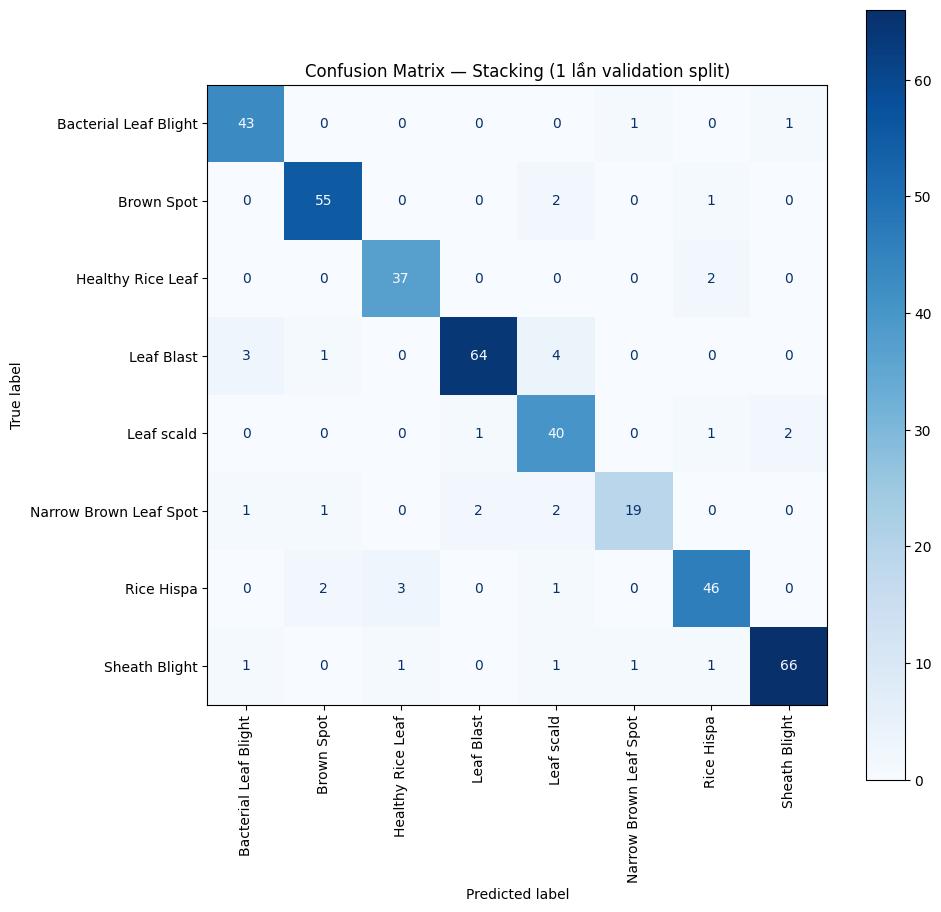

In [18]:
cm = confusion_matrix(y_valid, pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(label2id.keys())
)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(xticks_rotation=90, ax=ax, cmap="Blues")
plt.title(f"Confusion Matrix — {diagnostic_name} (1 lần validation split)")
plt.show()


## 11. Đánh giá nghiêm ngặt bằng Stratified 5-Fold Cross-Validation


In [ ]:
cv_models = {
    "SVM": Pipeline(build_preprocessing_steps() + [("clf", best_svm_clf)]),
    "ExtraTrees": Pipeline(build_preprocessing_steps() + [("clf", extra_clf)]),
    "RandomForest": Pipeline(build_preprocessing_steps() + [("clf", best_rf_clf)]),
    "VotingSoft": Pipeline(build_preprocessing_steps() + [("clf", VotingClassifier(
        estimators=[("svm", best_svm_clf), ("et", extra_clf), ("rf", best_rf_clf)],
        voting="soft",
        weights=[1, 1, 1]
    ))]),
    "Stacking": Pipeline(build_preprocessing_steps() + [("clf", StackingClassifier(
        estimators=[("svm", best_svm_clf), ("et", extra_clf), ("rf", best_rf_clf)],
        final_estimator=SVC(probability=True, random_state=SEED, class_weight="balanced"),
        cv=5,
        n_jobs=-1
    ))]),
}

cv_rows = []
for name, pipe in cv_models.items():
    scores = cross_validate(
        pipe, X, y,
        cv=cv5,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1
    )
    cv_rows.append([
        name,
        scores["test_accuracy"].mean(), scores["test_accuracy"].std(),
        scores["test_f1_macro"].mean(), scores["test_f1_macro"].std()
    ])

cv_results = pd.DataFrame(
    cv_rows,
    columns=["Model", "Acc_mean", "Acc_std", "F1_mean", "F1_std"]
)
cv_results.sort_values("F1_mean", ascending=False, inplace=True)
cv_results


In [ ]:
best_name = cv_results.iloc[0]["Model"]
best_model_pipeline = cv_models[best_name]

print("Model tốt nhất theo Stratified 5-Fold CV:", best_name)
print(cv_results.iloc[0])


## 12. Huấn luyện lại model tốt nhất trên toàn bộ dữ liệu train rồi lưu lại để nộp bài


In [ ]:
best_model_pipeline.fit(X, y)

joblib.dump(best_model_pipeline, "best_model_pipeline.pkl")
print("Đã lưu toàn bộ pipeline (scaler + feature selection + model) vào best_model_pipeline.pkl")


## 13. Trích xuất đặc trưng cho tập test và dự đoán

In [ ]:
Xtest_path = os.path.join(CACHE_DIR, "X_test_features_v10_lesion_texture.pkl")

if os.path.exists(Xtest_path):
    X_test = joblib.load(Xtest_path)
    print("Đã nạp đặc trưng test từ cache:", X_test.shape)
else:
    X_test_list = []
    start = time.time()

    for _, row in tqdm(test_df.iterrows(), total=len(test_df)):
        X_test_list.append(extract_features(row["path"]))

    X_test = np.array(X_test_list, dtype=np.float32)
    joblib.dump(X_test, Xtest_path)

    print(X_test.shape)
    print("Thời gian trích xuất test:", round(time.time() - start, 1), "giây")

In [ ]:
pred = best_model_pipeline.predict(X_test)


In [ ]:
submission = pd.DataFrame({
    "image_id": test_df.image_id,
    "label": pred.astype(int)  
})

assert submission["label"].between(0, 7).all(), "Co gia tri label ngoai khoang 0-7!"
assert len(submission) == len(test_df), "Thieu/du dong so voi test_df!"

submission.to_csv("submission.csv", index=False)
print(submission["label"].dtype)
submission.head()